# 09 · Does clean data help the model?

*A controlled experiment that trains the same model on clean, broken and repaired data.*

Notebooks 04 and 05 built faults and checks and scored the checks with recall and precision. Those numbers say how often a verdict is right. They don't say whether any of it matters to a model. The project's definition of a good value is one a model would learn the right thing from, so this notebook asks the model directly.

The model is a small piece of **post-processing**, which is what forecasters call learning a correction to a weather model from its past errors. HRRR is good but it doesn't know that one airport sits in a cold hollow or that another gets a sea breeze at 2 pm. A model that sees HRRR's forecast plus the time and the station's location can learn those local corrections from history. We use **gradient boosting** (LightGBM), a fast and strong default for tables of features. It predicts how far the station's temperature sits from HRRR, and the prediction is HRRR plus that correction.

The experiment changes one thing only. Every **arm** trains the same model with the same settings on a different version of the 2021–2023 data, and every arm is tested on the same 2024 data that no fault touched. If one arm scores worse it's because the model learned something wrong in training. Five seeds give five different sets of planted faults so we can see the spread.

Before the experiment there's one more QA tool to build. Notebook 05 left us with a `break` annotation that marks every day near a lasting shift in a station's record. To act on a break we need to know where exactly it is and how big it is. Climate scientists solved that problem decades ago and call it **homogenization**, so the first half of this notebook builds a small version of it. The second half runs the experiment with eight arms:

| Arm | Training data (2021–2023) |
|---|---|
| clean | the true values with no planted faults |
| faulty | the observed values with one seed's planted faults |
| QA'd | faulty minus the hours QA marked quarantine |
| QA'd strict | faulty minus quarantine and suspect hours |
| random thinning | faulty minus as many hours as QA'd removed, picked at random |
| oracle | faulty minus exactly the planted fault hours, which no real QA can know |
| QA'd + drop segments | QA'd minus the stretches that break dating found to be off |
| QA'd + adjust segments | QA'd with those stretches shifted back into line |

What to look for: how much damage the faults do, how much of it each kind of cleaning undoes, and whether QA'd beats random thinning. That last comparison is the control. If QA'd only beats faulty because it has less data then random thinning would do just as well.

In [1]:
# Setup: identical in every notebook. Data lives in ../data, which git ignores.
import os
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data"))
os.makedirs(DATA_DIR, exist_ok=True)
print("Data directory:", DATA_DIR)

Data directory: /Users/ashu/Workspace/weather-data-lab/data


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from wxlab import stations as st, reference as ref, faults as fl, qa, experiment as ex

plt.rcParams["figure.dpi"] = 80
REF_DIR = Path(DATA_DIR) / "reference"
QA_DIR = Path(DATA_DIR) / "qa"
EX_DIR = Path(DATA_DIR) / "experiment"

# Inputs from notebooks 03-05: the matched table, climatology, station points and duplicates.
reference = ref.load(REF_DIR / "hrrr")
model_elev = pd.read_parquet(REF_DIR / "hrrr_model_elevation.parquet").set_index("station_id").model_elevation_m
hourly = st.load_standardized(Path(DATA_DIR) / "standardized" / "isd", years=range(2021, 2025))
matched = ref.match(hourly, reference, model_elev).dropna(subset=["hrrr_air_temperature"])
older = st.load_standardized(Path(DATA_DIR) / "standardized" / "isd", station_ids=matched.station_id.unique(), years=range(2015, 2021))
clim = qa.climatology(older)
points = pd.read_parquet(REF_DIR / "station_points.parquet")
dups = fl.duplicate_pairs(matched)
names = st.load_station_history(Path(DATA_DIR) / "meta").drop_duplicates("station_id").set_index("station_id")["name"].str.title()

# Notebook 05's checks on the real data, saved there.
real_flags = pd.read_parquet(QA_DIR / "real_flags.parquet")
real_cp = pd.read_parquet(QA_DIR / "real_changepoint.parquet")
real_verdict = real_flags.set_index(["station_id", "time"]).verdict
print(f"{len(matched):,} matched station-hours at {matched.station_id.nunique()} stations")

5,249,635 matched station-hours at 165 stations


The setup cell loads the same inputs as notebook 05: the matched station and HRRR table, each station's 2015–2020 climatology, the station locations and the duplicate pairs. It also loads notebook 05's verdicts on the real data. Those are used twice here, once to look for breaks in real stations and once to clean the test set.

## Step 1 · From break days to break dates

A **break** (or inhomogeneity) is a point where a station's record changes character and stays changed. A new sensor, a move across the airfield or a new radiation shield can each shift the readings by a fraction of a degree or more. Hour by hour nothing looks wrong. The values are plausible, they follow the weather and they agree with HRRR to within the usual noise. Only the long-run level has moved.

Notebook 05 caught breaks with two shift detectors that compare the mean of the 30 or 90 days after each day with the mean of the days before. When both detectors fire (one against HRRR and one against the neighbours) the day gets a `break` annotation. That's good for spotting a break but bad for locating it. A two-window test fires on every day near the shift, so one break shows up as a run of flagged days that can last weeks. A run like that is called a break **episode** here.

Climate datasets deal with this through homogenization. NOAA's pairwise homogenization algorithm, which adjusts the monthly temperature records in GHCN-Monthly, compares each station with many neighbours, finds the date of each break and then shifts the older part of the record so it lines up with the newest part (Menne & Williams 2009). We do a small version of the same thing in three steps that live in `wxlab.qa`:

1. **Date each episode.** Inside each episode take the day where the before/after difference against the neighbours is biggest. That's where the level changes.
2. **Cut the record into segments** at those dates and measure each segment's level. The level is the median daily difference from the neighbours after removing the station's own seasonal cycle. Then prune. A break that separates two segments less than 0.5 °C apart doesn't count, and neither does one that leaves a segment shorter than 30 days. Pruning goes weakest first and repeats until every break left is real by those rules. A shift that comes back after a while ends up as two breaks around a short segment that's off.
3. **Measure each segment against the newest one.** The newest segment is the **reference**, by the usual convention that the latest instruments are the ones to trust. A segment's offset is its level minus the reference level. A segment more than 0.5 °C off is marked bad.

Here's that on seed 0's planted data.

In [3]:
planted, catalogue, _, holdout = fl.load(DATA_DIR, seed=0)
nbrs = qa.neighbours(points[points.station_id.isin(planted.station_id.unique())], dups)
flags, _, cp = qa.run_checks(planted, clim, nbrs)
dates = qa.break_dates(flags, cp)
segs = qa.segments(cp, dates)
print(f"{len(dates)} break episodes at {dates.station_id.nunique()} stations")
print(f"{int((segs.groupby('station_id').size() - 1).sum())} breaks survive pruning; "
      f"{segs[segs.bad].station_id.nunique()} stations have at least one segment that's off")

90 break episodes at 47 stations
30 breaks survive pruning; 21 stations have at least one segment that's off


Ninety episodes collapse into thirty breaks once the weak ones are pruned. Twenty-one stations end up with at least one segment that's off. Seed 0 planted 15 level faults (steps, drifts and biases), so some of those 21 are faults and some are false alarms. Step 2 counts which.

The picture makes it concrete. The top panel is Gnoss Field, a small airport north of San Francisco where seed 0 planted a −2 °C step in December 2022. The grey line is the station's daily difference from its neighbours. The orange bands are the break episodes the checks found. The ones in December 2022 are only a few days wide because the step is sharp, and the one around the end of 2023 is wider. The dashed lines are the dated breaks. The step drops the level by 2 °C and the end of the fault at the start of 2024 lifts it back. Both get dated within a day. The bars show each segment's level. The 2024 segment is the reference (blue) and the faulty segment is red at about −2 °C from it.

There's a catch in the same panel. The segment before the fault is red too, about half a degree below 2024. That's not planted. Gnoss Field really does sit a little warmer against its neighbours in 2024 than in 2021–2022. Is that a real sensor change or just a different year? The data can't say. It's the weak point of the reference convention: whatever is different about the newest segment gets treated as the truth.

The bottom panel is real data from notebook 03's naval airfield, which reported a stuck 2 °F for weeks at a time. The tool cuts out the broken months cleanly and measures them at 10–20 °C below the reference. The hourly checks had already quarantined most of those hours. What break dating adds is the shape of the problem, which is when it started, when it ended and how big it was.

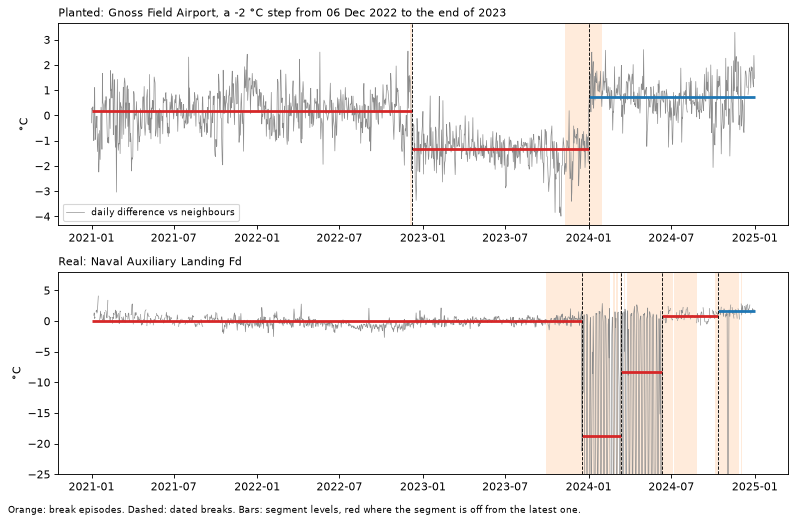

In [4]:
real_dates = qa.break_dates(real_flags, real_cp)
real_segs = qa.segments(real_cp, real_dates)

def show(ax, cp, dates, segs, sid, title, ylim=None):
    s = cp[cp.station_id == sid].set_index("day").adj
    ax.plot(s.index, s, lw=0.6, color="0.55", label="daily difference vs neighbours")
    for e in dates[dates.station_id == sid].itertuples():
        ax.axvspan(e.first_day, e.last_day, color="tab:orange", alpha=0.15, lw=0)
    for x in segs[segs.station_id == sid].itertuples():
        ax.hlines(x.level, x.start, x.end, color="tab:red" if x.bad else "tab:blue", lw=2.5)
        if x.segment > 0:
            ax.axvline(x.start, color="k", lw=0.8, ls="--")
    ax.set_title(title, fontsize=10, loc="left")
    ax.set_ylabel("°C")
    if ylim:
        ax.set_ylim(*ylim)

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5))
f = catalogue[catalogue.station_id == "72040600135"].iloc[0]
show(axes[0], cp, dates, segs, "72040600135",
     f"Planted: {names['72040600135']}, a {f.fault_size:+.0f} °C step from {f.first_affected:%d %b %Y} to the end of 2023")
show(axes[1], real_cp, real_dates, real_segs, "72290993115", f"Real: {names['72290993115']}", ylim=(-25, 8))
axes[0].legend(loc="lower left", fontsize=8)
fig.text(0.01, 0.005, "Orange: break episodes. Dashed: dated breaks. Bars: segment levels, red where the segment is off from the latest one.", fontsize=8)
plt.tight_layout(rect=(0, 0.02, 1, 1)); plt.show()

## Step 2 · Does break dating find the planted faults?

The planted faults are an answer key for this tool too. For every step, bias and drift across 20 seeds we ask two things. Did any bad segment touch the fault? And how wrong are the fault's hours before and after shifting each bad segment back by its offset? The error is the median of |observed − true| over the fault's hours, so 2.00 before means the fault was 2 °C and 0.13 after means the repair left about a tenth of a degree.

The untouched stations measure the cost. Any adjustment there is a false one.

In [5]:
bk, untouched = ex.evaluate_breaks(matched, clim, points, dups, seeds=range(20), out_dir=EX_DIR / "breaks")
bk["size"] = bk.fault_size.abs()
table = (bk.groupby(["fault_type", "size"])
           .agg(faults=("found", "size"), found=("found", "mean"),
                error_before=("error_before", "median"), error_after=("error_after", "median")))
print("level faults over 20 seeds (errors are median °C over each fault's hours)")
print(table.round(2).to_string())
print()
print(f"untouched stations: {(untouched.share_bad > 0).mean():.0%} get at least one false segment; "
      f"{untouched.share_bad.mean():.1%} of their hours are adjusted, "
      f"by {untouched[untouched.share_bad > 0].mean_abs_offset.mean():.2f} °C on average at those stations")

level faults over 20 seeds (errors are median °C over each fault's hours)
                 faults  found  error_before  error_after
fault_type size                                          
bias       0.5       20   0.35          0.50         0.50
           1.0       23   0.78          1.00         0.22
           2.0       28   0.96          2.00         0.13
           3.0       29   0.93          3.00         0.19
drift      0.5       25   0.16          0.25         0.25
           1.0       24   0.12          0.50         0.50
           2.0       27   0.52          1.00         0.99
           3.0       24   0.71          1.50         0.87
step       0.5       26   0.19          0.50         0.50
           1.0       19   0.58          1.00         1.00
           2.0       29   0.97          2.00         0.19
           3.0       26   1.00          3.00         0.30

untouched stations: 12% get at least one false segment; 4.9% of their hours are adjusted, by 0.28 °C on average a

Steps and biases of 2 °C or more are found almost every time, and the repair takes their error from 2–3 °C down to 0.1–0.3 °C. At 1 °C it's mixed. Biases of 1 °C get repaired most of the time, but more than half of the 1 °C steps keep their full error. At 0.5 °C almost nothing is found, which matches notebook 05: half a degree hides inside the normal wander of a station against its neighbours.

The bias line needs care. In notebook 05 a constant bias was close to undetectable because it starts on the first day of the data and there's no "before" to compare with. Here it's easy. That's because the planted bias stops at the end of 2023, so the 2024 data gives the record a clean "after". A real bias that's still in the newest data would look like the station's honest level and nothing here would find it.

Drifts are only partly fixed. A drift is a ramp and a segment is flat, so at best the repair takes out the ramp's average. A 3 °C drift goes from a median error of 1.5 °C to about 0.9 °C.

The false adjustments are small. About one untouched station in eight gets a segment marked bad, which touches about 5% of the untouched hours, and the adjustment at those stations averages 0.28 °C. Compared with a 2 °C fault that's a good trade, but it isn't free.

## Step 3 · Breaks in the real data

The same tool on all 165 real stations:

In [6]:
bad = real_segs[real_segs.bad].assign(name=lambda d: d.station_id.map(names))
print(f"real data: {len(real_dates)} episodes at {real_dates.station_id.nunique()} stations, "
      f"{int((real_segs.groupby('station_id').size() - 1).sum())} breaks kept, "
      f"{bad.station_id.nunique()} stations with a segment that's off")
top = bad.reindex(bad.offset.abs().sort_values(ascending=False).index).head(8)
print(top.assign(start=top.start.dt.date, end=top.end.dt.date)[["name", "start", "end", "days", "offset"]]
      .round(2).to_string(index=False))

real data: 142 episodes at 59 stations, 52 breaks kept, 30 stations with a segment that's off
                      name      start        end  days  offset
Naval Auxiliary Landing Fd 2023-12-17 2024-03-12    86  -20.53
Naval Auxiliary Landing Fd 2024-03-12 2024-06-11    91  -10.10
Bridgeport Sonora Junction 2023-01-20 2023-02-22    33   -2.77
  Marine Corps Air Station 2021-10-22 2021-11-21    30    2.36
  Mammoth Yosemite Airport 2023-04-18 2023-06-11    54    1.88
Naval Auxiliary Landing Fd 2021-01-01 2023-12-17  1025   -1.77
  Mammoth Yosemite Airport 2023-01-21 2023-02-23    33   -1.76
  Nalf/F. Sherman Fld Arpt 2023-08-21 2023-12-21   121    1.68


Thirty real stations get a segment that's off. The naval airfield's stuck months lead by a long way. After that the list is a mix that needs a human look, the same as notebook 05's alarms.

Some of it is probably weather. Bridgeport and Mammoth are Sierra stations, and their off segments fall between January and June 2023, the winter and spring of one of the deepest Sierra snowpacks on record. Snow changes how the ground heats and cools and that differs from valley to valley, so the neighbours don't share it and HRRR's smoother snow field gets it wrong in both directions. That would be a representativeness change and not a broken sensor. Some of it matches notebook 05's suspects. Two military airfields, Camp Pendleton's Marine Corps air station and the naval landing field on San Clemente Island, have segments 1–2.5 °C off for one to four months. North Island NAS is also on the full list with its cold episode from late 2021. And the long low segment at the naval airfield covering 2021–2023 says the station sat about 1.8 °C colder before its trouble began than after. That could be a sensor replaced during the repairs, which is exactly the kind of break homogenization exists for.

So on real data break dating is a strong lead and not a verdict. In the experiment below it's used anyway, the same way on every seed, and the untouched stations' false segments are part of what it costs.

## Step 4 · The experiment

Now the main question. For each of five seeds, `wxlab.experiment.run_seed` plants that seed's faults, runs every check, dates the breaks, builds the eight training sets and trains one LightGBM model per arm. The model gets ten features: HRRR's height-corrected temperature, its dew point and the gap between them, the hour, the day of the year as a sine and cosine, and the station's latitude, longitude, elevation and height above HRRR's terrain. It never sees the station's own reading, which is the target.

The test set is 2024 at all 107 baseline stations. The faults stop at the end of 2023 so 2024 is the truth for every arm. One detail matters here. 2024 has real faults of its own (notebook 05 found San Nicolas Island reading 0.0 °C for weeks), so the hours the real-data QA quarantined are taken out of the test set, the same way for every arm. Scores are split four ways:

- **training stations**: the 86 stations the model trained on.
- **faulty stations**: the 27 of those that had a planted fault. This is where damage should show.
- **held-out stations**: 21 stations the model never saw, to test whether bad data at some stations hurts predictions everywhere.
- **storm hours**: the windy and wet hours, to see if storm gaps left the model weak on storms.

There's also a row for raw HRRR with no model. That's the baseline any post-processing has to beat. Each seed takes about a minute and a half, and the results are cached one folder per seed.

In [7]:
out = ex.run_seeds(matched, clim, points, dups, real_verdict, seeds=range(5), out_dir=EX_DIR)
res, per_station = out["results"], out["stations"]
order = ["hrrr"] + ex.ARMS
summary = (res.groupby(["arm", "group"]).rmse.agg(["mean", "std"])
             .apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1).unstack("group")
             .reindex(order)[["training stations", "faulty stations", "held-out stations", "storm hours"]])
print("test RMSE on 2024 in °C, mean ± sd over 5 seeds")
print(summary.to_string())

test RMSE on 2024 in °C, mean ± sd over 5 seeds
group              training stations faulty stations held-out stations    storm hours
arm                                                                                  
hrrr                   1.435 ± 0.000   1.449 ± 0.051     1.392 ± 0.000  1.249 ± 0.000
clean                  1.119 ± 0.000   1.137 ± 0.021     1.412 ± 0.004  1.187 ± 0.001
faulty                 1.275 ± 0.056   1.569 ± 0.133     1.473 ± 0.045  1.320 ± 0.057
qa                     1.257 ± 0.062   1.522 ± 0.151     1.467 ± 0.039  1.311 ± 0.061
qa_strict              1.240 ± 0.059   1.479 ± 0.147     1.447 ± 0.023  1.286 ± 0.046
random                 1.275 ± 0.056   1.569 ± 0.133     1.465 ± 0.049  1.320 ± 0.058
oracle                 1.138 ± 0.009   1.199 ± 0.032     1.400 ± 0.019  1.190 ± 0.006
qa_drop_segments       1.162 ± 0.027   1.263 ± 0.088     1.427 ± 0.030  1.199 ± 0.005
qa_adjust_segments     1.129 ± 0.009   1.174 ± 0.029     1.434 ± 0.028  1.196 ± 0.009


Start at the top. Raw HRRR has an RMSE of about 1.44 °C at the training stations. The model trained on clean data brings it to 1.12, so post-processing earns about 0.3 °C. Trained on faulty data the model only gets to 1.28. At the faulty stations it's 1.57, which is worse than not using a model at all. The model learned each broken station's broken offset and applied it faithfully to 2024.

The held-out stations barely notice. Clean is 1.41 and faulty 1.47 there, with a spread of ±0.05 between seeds. A station the model never saw only learns from its neighbours' general patterns and not from any one station's offset. Notice too that even the clean model is a touch worse than raw HRRR at held-out stations (1.41 against 1.39). The corrections it learns are mostly station-specific and don't carry to new places, so a model like this should only be trusted at stations it has trained on.

The plot shows each seed as a dot and the mean as a bar.

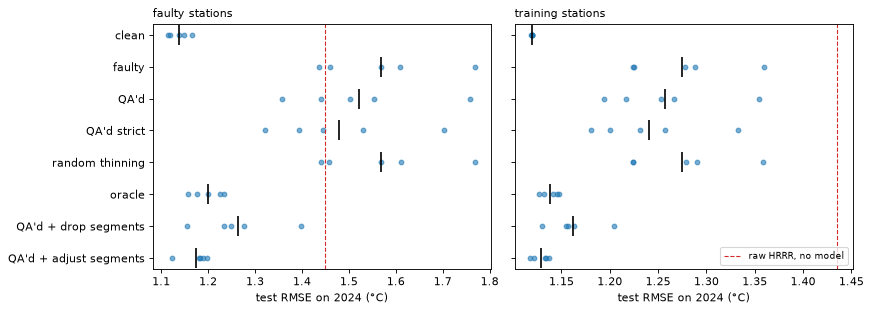

In [8]:
arms = ex.ARMS
labels = {"clean": "clean", "faulty": "faulty", "qa": "QA'd", "qa_strict": "QA'd strict", "random": "random thinning",
          "oracle": "oracle", "qa_drop_segments": "QA'd + drop segments", "qa_adjust_segments": "QA'd + adjust segments"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, g in zip(axes, ["faulty stations", "training stations"]):
    d = res[res.group == g]
    for i, a in enumerate(arms):
        v = d[d.arm == a].rmse
        ax.scatter(v, [i] * len(v), s=18, color="tab:blue", alpha=0.6)
        ax.scatter(v.mean(), i, marker="|", s=300, color="k")
    h = d[d.arm == "hrrr"].rmse.mean()
    ax.axvline(h, color="tab:red", ls="--", lw=1, label="raw HRRR, no model")
    ax.set_title(g, fontsize=10, loc="left"); ax.set_xlabel("test RMSE on 2024 (°C)")
axes[1].legend(loc="lower right", fontsize=8)
axes[0].set_yticks(range(len(arms))); axes[0].set_yticklabels([labels[a] for a in arms]); axes[0].invert_yaxis()
plt.tight_layout(); plt.show()

The arms fall into three groups.

**Removing hours barely helps.** QA'd brings the faulty stations from 1.57 to 1.52 and QA'd strict to 1.48. Random thinning doesn't move at all, so what QA removes is genuinely bad data. There's just not enough of it to matter, and the reason is in the next step.

**Removing or repairing segments helps a lot.** Dropping bad segments gets to 1.26 and adjusting them gets to 1.17, close to the clean model's 1.14.

**Adjusting beats the oracle.** The oracle removes every faulty hour and still scores 1.20. Removing a planted bias means removing all three years of that station's data, and then the model has nothing to learn that station's local correction from. Adjusting keeps the hours and fixes their level, so the station stays in the training set.

## Step 5 · Which faults do the damage?

To see where the damage comes from we break the faulty stations down by fault type. The table shows how much worse each arm is than the clean arm at those stations, so 0 means no damage.

In [9]:
cat = out["catalogue"][["seed", "station_id", "fault_type"]]
ps = per_station.merge(cat, on=["seed", "station_id"])
wide = ps.pivot_table(index=["seed", "station_id", "fault_type"], columns="arm", values="rmse").reset_index()
for a in ["faulty", "qa", "qa_strict", "qa_drop_segments", "qa_adjust_segments", "oracle"]:
    wide[a] = wide[a] - wide["clean"]
damage = wide.groupby("fault_type")[["faulty", "qa", "qa_strict", "qa_drop_segments", "qa_adjust_segments", "oracle"]].mean()
damage.insert(0, "stations", wide.groupby("fault_type").size())
print("extra test RMSE vs the clean arm at the faulty stations, by fault type (°C, mean over stations and seeds)")
print(damage.round(3).to_string())

extra test RMSE vs the clean arm at the faulty stations, by fault type (°C, mean over stations and seeds)
arm          stations  faulty     qa  qa_strict  qa_drop_segments  qa_adjust_segments  oracle
fault_type                                                                                   
bias               25   0.964  0.961      0.923             0.229               0.041   0.242
drift              25   0.040  0.039      0.026             0.004              -0.001   0.002
step               25   0.463  0.451      0.399             0.092               0.024   0.030
storm_gaps         20   0.003  0.002     -0.000            -0.006              -0.013  -0.002
stuck              20   0.006  0.003      0.003             0.001               0.002  -0.002
time_offset        20   0.376  0.134      0.012             0.251               0.148  -0.001


This explains everything above.

**Biases and steps do almost all the damage**, about 1 °C and 0.5 °C of extra RMSE. They're also the faults the hour-level checks can't see, so the quarantine verdict leaves them in. Segment repair takes them to 0.04 and 0.02.

**Time offsets hurt too** (0.38) and here it's the other way round. The timing check catches them, so QA'd cuts the damage to 0.13 and QA'd strict to about zero. Segments do nothing for a time offset because the mean doesn't move. The drop-segments column even looks worse than QA'd for time offsets. That's 20 stations over five seeds, so it's likely noise.

**Stuck sensors, storm gaps and drifts barely matter to this model.** A stuck run is a few hours to a week in three years. A drift's average error is small and short. Storm gaps take away some storm hours but the other 80-odd stations still cover every storm. That's a useful lesson in its own right. A fault can be important for a dataset (a monitoring dashboard should still flag storm gaps) and still not matter to a particular model.

## Step 6 · How much of the gap does each arm close?

Last, the headline number per seed: the share of the gap between the faulty arm and the clean arm that each kind of cleaning closes at the faulty stations. Zero means no better than faulty and one means as good as clean.

In [10]:
p = res[res.group == "faulty stations"].pivot_table(index="seed", columns="arm", values="rmse")
gap = p.faulty - p.clean
def closed(a):
    return ((p.faulty - p[a]) / gap)
print("share of the faulty-vs-clean gap closed at the faulty stations, per seed")
print(pd.DataFrame({a: closed(a) for a in ["random", "qa", "qa_strict", "qa_drop_segments", "qa_adjust_segments", "oracle"]})
        .round(2).to_string())

share of the faulty-vs-clean gap closed at the faulty stations, per seed
      random    qa  qa_strict  qa_drop_segments  qa_adjust_segments  oracle
seed                                                                       
0      -0.00  0.12       0.17              0.46                0.89    0.94
1      -0.00  0.14       0.27              0.70                0.85    0.81
2       0.01  0.07       0.22              0.62                0.95    0.77
3      -0.01  0.27       0.39              0.68                0.83    0.71
4       0.00  0.02       0.10              0.94                0.99    0.94


Random thinning closes nothing on every seed. Quarantine closes 2–27% of the gap and the strict version 10–39%. Dropping segments closes 46–94%. Adjusting closes 83–99%, more than the oracle on four of the five seeds. From random to adjust the order is the same on every seed even though the planted faults differ, so it isn't luck.

## What it adds up to

Cleaner data does help the model, and the experiment shows which cleaning helps. The faults that hurt this model most are the quiet ones: a station that reads a degree or two off for months while every hour looks plausible. Hour-level QA can't see them by design. What fixes them is a different kind of tool that looks at the record as a whole, finds where its level changes and repairs it. Throwing data away is a weaker fix than repairing it, because a model that learns local corrections needs every station's data.

The big caveat is the reference segment. Every repair here lines the past up with 2024 and the planted faults end in 2023, so the newest segment is always the truth. In real data that's an assumption. A station whose sensor broke last month has a broken reference, and repairing to it would spread the fault backwards. Real homogenization handles that with metadata, many neighbours and a person looking at the result. Here it's the main reason the real-data breaks in step 3 are leads and not verdicts.

## What surprised me

**A model trained on faulty data was worse than no model.** At the faulty stations the faulty arm scored 1.57 °C against raw HRRR's 1.45. Post-processing learns each station's offset and faithfully learns the broken ones too.

**Repairing beat the oracle.** Even knowing exactly which hours were wrong, removing them did worse than shifting them back. A station with no training data can't get its local correction.

**The quarantine verdict hardly mattered to the model.** It's right about the hours it flags and random removal proves that. But the damage is in faults that hours can't show.

**Held-out stations didn't care.** Bad data at 27 stations barely touched predictions at 21 stations the model never saw.

**Snow probably made real "breaks".** Mountain stations got off segments during the Sierra's huge 2023 snow year. The sensors were most likely fine and the ground changed under them.

## Check yourself

<details><summary>Why is random thinning needed when QA'd already beats faulty?</summary>
QA'd has less data than faulty. Less data can change a model's score by itself, through less overfitting or different weights between stations. Random thinning removes the same number of hours without knowing which are bad. Because it doesn't improve on faulty at all, QA'd's small gain comes from removing the right hours.
</details>

<details><summary>Why does the oracle lose to the adjust arm?</summary>
For a bias the oracle removes the station's whole training record, so the model can't learn that station's local correction and falls back on what its neighbours suggest. The adjust arm keeps the record with its level fixed, so the station's own pattern is still learned.
</details>

<details><summary>Why would segment adjustment be risky on real data?</summary>
Offsets are measured against the newest segment, which is assumed to be right. If the newest segment is the broken one, every older (correct) segment gets shifted to match the fault. The planted faults here always end before 2024 so the experiment never meets that case.
</details>

<details><summary>Storm gaps barely hurt this model. Should QA stop checking for them?</summary>
No. They didn't hurt this model on this metric, because the other stations covered the storms and RMSE averages over all hours. A model trained only on extreme events, or a dataset used to count storms, would be hurt directly. Whether a fault matters depends on what the data is used for.
</details>

New terms from this notebook are in [`docs/glossary.md`](../docs/glossary.md).